# Your First Sentiment Classifier
**SkillMe Machine Learning Virtual Internship — Week 1**

Predict whether an IMDB movie review is positive or negative using Bag-of-Words and Logistic Regression.

**Dataset:** IMDB Dataset of 50K Movie Reviews (Kaggle)  
**Target:** `sentiment` — positive = 1, negative = 0  
**Evaluation:** 80/20 train-test split, `random_state=42`

> Download the Kaggle CSV and place it in the same folder as this notebook. Rename it `IMDB Dataset.csv` if needed.

## 1. Import libraries

In [1]:
import re
import string
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

pd.set_option("display.max_colwidth", 200)
RANDOM_STATE = 42

## 2. Load the dataset

In [3]:
# Download "IMDB Dataset of 50K Movie Reviews" from Kaggle:
# https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews

df = pd.read_csv("IMDB Dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:")
print(df.isna().sum())

Dataset shape: (50000, 2)


,review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me...",positive
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire p...",positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic, but the dialogue i...",positive
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenl...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portrait about human relations. This is a movie that seems to be telling us what mone...",positive



Missing values:
review       0
sentiment    0
dtype: int64


## 3. Explore the reviews
Print three full reviews, inspect the sentiment balance, and plot review lengths.

REVIEW 1 — POSITIVE

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the s

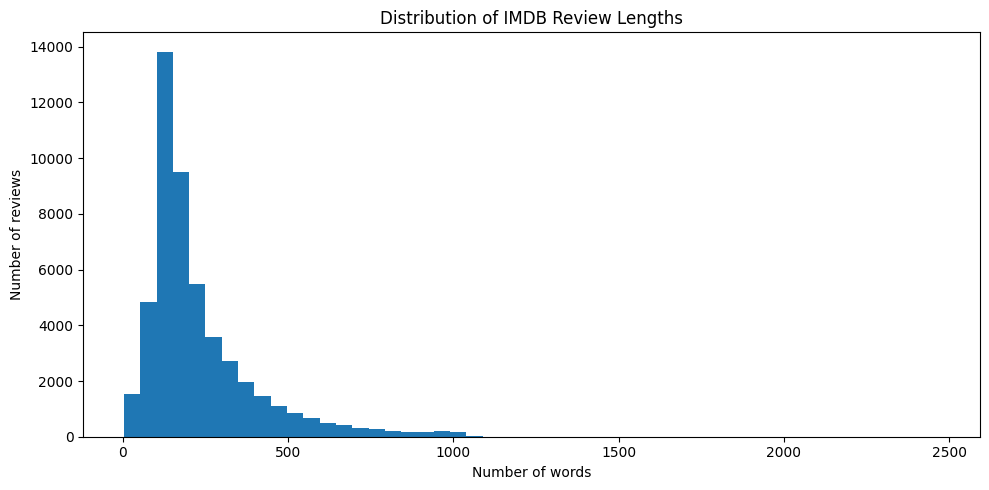

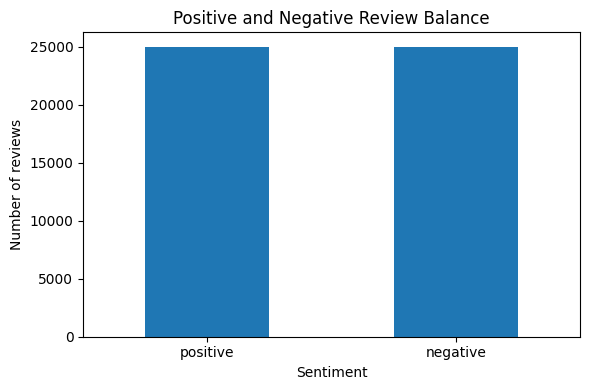

In [4]:
for i in range(3):
    print(f"REVIEW {i + 1} — {df.loc[i, 'sentiment'].upper()}\n")
    print(df.loc[i, "review"])
    print("\n" + "=" * 100 + "\n")

print("Sentiment counts:")
print(df["sentiment"].value_counts())

df["review_length"] = df["review"].astype(str).str.split().str.len()

plt.figure(figsize=(10, 5))
plt.hist(df["review_length"], bins=50)
plt.title("Distribution of IMDB Review Lengths")
plt.xlabel("Number of words")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

df["sentiment"].value_counts().plot(kind="bar", rot=0, figsize=(6, 4))
plt.title("Positive and Negative Review Balance")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

## 4. Clean the text
Lowercase text, remove HTML break tags and other HTML tags, and remove punctuation. We keep spaces between words.

In [5]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<br\s*/?>", " ", text)  # remove IMDB line breaks
    text = re.sub(r"<[^>]+>", " ", text)      # remove remaining HTML tags
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Test the cleaner on three reviews
for i in range(3):
    print(f"ORIGINAL {i + 1}:\n{df.loc[i, 'review'][:500]}\n")
    print(f"CLEANED {i + 1}:\n{clean_text(df.loc[i, 'review'])[:500]}")
    print("\n" + "-" * 80 + "\n")

df["clean_review"] = df["review"].apply(clean_text)
df["label"] = df["sentiment"].map({"positive": 1, "negative": 0})

assert df["label"].notna().all(), "Unexpected sentiment labels found."
print(df[["sentiment", "label", "clean_review"]].head())

ORIGINAL 1:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

CLEANED 1:
one of the other reviewers has mentioned that after watching just 1 oz episode youll be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was its brutality and unflinching scenes of violence which set in right from the word go trust me this is not a show for the faint hearted or timid this show pulls no punches with regards to drugs sex or violence its is hardcore in the classic use of the word it is called oz as that 

## 5. Split into training and test sets
Split before fitting the vectorizer to prevent test-data leakage.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"],
    df["label"].astype(int),
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

print("Training reviews:", len(X_train))
print("Test reviews:", len(X_test))

Training reviews: 40000
Test reviews: 10000


## 6. Convert text into Bag-of-Words features
Fit `CountVectorizer` on training text only. Then transform the test text using the learned vocabulary.

In [7]:
vectorizer = CountVectorizer(max_features=10000)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Training matrix shape:", X_train_vec.shape)
print("Test matrix shape:", X_test_vec.shape)
print("Example vocabulary terms:", list(vectorizer.get_feature_names_out()[:30]))

Training matrix shape: (40000, 10000)
Test matrix shape: (10000, 10000)
Example vocabulary terms: ['007', '010', '10', '100', '1000', '101', '1010', '11', '110', '12', '13', '13th', '14', '15', '150', '16', '17', '18', '18th', '19', '1920s', '1930', '1930s', '1931', '1932', '1933', '1934', '1936', '1938', '1939']


## 7. Train Logistic Regression and evaluate

Test accuracy: 88.1100%

Classification report:
              precision    recall  f1-score   support

    negative       0.88      0.88      0.88      5000
    positive       0.88      0.88      0.88      5000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



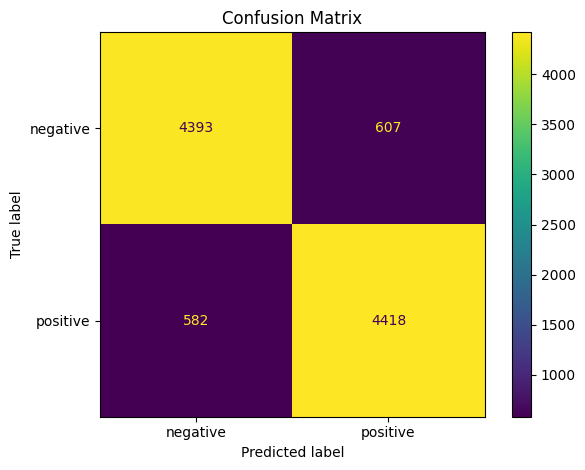

Goal achieved: test accuracy is above 85%.


In [8]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

y_pred = model.predict(X_test_vec)
accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.4%}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["negative", "positive"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["negative", "positive"], values_format="d"
)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

if accuracy > 0.85:
    print("Goal achieved: test accuracy is above 85%.")
else:
    print("The accuracy target was not reached yet. Review the cleaning and model settings.")

## 8. Predict sentiment for your own sentences
Try five examples, including the required tricky phrase **“not bad at all”**. Check whether the model's predictions make sense.

In [9]:
def predict_sentiment(text):
    cleaned = clean_text(text)
    features = vectorizer.transform([cleaned])
    prediction = model.predict(features)[0]
    probability_positive = model.predict_proba(features)[0][1]
    label = "positive" if prediction == 1 else "negative"
    return label, probability_positive

custom_sentences = [
    "This movie was fantastic, I loved every minute of it.",
    "The acting was terrible and the story made no sense.",
    "Not bad at all.",
    "I expected much more, but it was disappointing.",
    "A beautiful film with excellent performances."
]

for sentence in custom_sentences:
    sentiment, prob_positive = predict_sentiment(sentence)
    print(f"Sentence: {sentence}")
    print(f"Prediction: {sentiment} | Positive probability: {prob_positive:.3f}")
    print("-" * 80)

Sentence: This movie was fantastic, I loved every minute of it.
Prediction: positive | Positive probability: 0.886
--------------------------------------------------------------------------------
Sentence: The acting was terrible and the story made no sense.
Prediction: negative | Positive probability: 0.203
--------------------------------------------------------------------------------
Sentence: Not bad at all.
Prediction: negative | Positive probability: 0.283
--------------------------------------------------------------------------------
Sentence: I expected much more, but it was disappointing.
Prediction: negative | Positive probability: 0.247
--------------------------------------------------------------------------------
Sentence: A beautiful film with excellent performances.
Prediction: positive | Positive probability: 0.927
--------------------------------------------------------------------------------
